In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
day9_input_path = "../data/analysis_data/APL_Day5_Delay_Risk_Analysis.csv"

df_day9 = pd.read_csv(
    day9_input_path,
    encoding="cp1252",
    low_memory=False
)

print("Day 9 dataset loaded successfully.")
print("Dataset shape:", df_day9.shape)

display(df_day9.head())

Day 9 dataset loaded successfully.
Dataset shape: (180519, 56)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Fname,Customer Id,Customer Lname,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode,Shipping_Delay_Days,Is_Delayed,Is_On_Time,Early_Delivery_Days,Delay_Severity,Delivery_Efficiency_Ratio,Revenue_Per_Unit,Profit_Margin,Discount_Level,Region_Market,Shipping_Mode_Rank,Is_Corporate_Customer,Order_Quantity_Category,Operational_Risk_Profile,Delivery_Status,Risk_Status
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,EE. UU.,Richard,1,Hernandez,Consumer,TX,6303 Heather Plaza,78521.0,3,Footwear,25.953648,-97.507683,Pacific Asia,Mumbai,India,1,27.50,0.06,99.99,0.34,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class,2,1,0,0,Major Delay,0.666667,99.99,0.319412,Low Discount,Pacific Asia - South Asia,4,0,Large,High Risk - Slower Shipping,Delayed,High Risk
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,31.99,0.16,39.99,0.29,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class,0,0,1,0,On Time / Early,1.000000,39.99,0.243611,Medium Discount,LATAM - Central America,4,0,Large,Lower Risk,On Time,Low Risk
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,18.00,0.09,199.99,0.48,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class,0,0,1,0,On Time / Early,1.000000,199.99,0.436822,Low Discount,LATAM - Central America,4,0,Small,Lower Risk,On Time,Low Risk
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,24.00,0.12,199.99,-0.24,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class,2,1,0,0,Major Delay,0.666667,199.99,-0.209460,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,10.00,0.20,50.00,0.25,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class,2,1,0,0,Major Delay,0.666667,50.00,0.200000,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk


## Dataset Overview & Validation

In [3]:
print("Total rows:", len(df_day9))
print("Total columns:", len(df_day9.columns))
print("Duplicate rows:", df_day9.duplicated().sum())

print("\nDataset columns:")
print(df_day9.columns.tolist()) 

Total rows: 180519
Total columns: 56
Duplicate rows: 0

Dataset columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Product Price', 'Shipping Mode', 'Shipping_Delay_Days', 'Is_Delayed', 'Is_On_Time', 'Early_Delivery_Days', 'Delay_Severity', 'Delivery_Efficiency_Ratio', 'Revenue_Per_Unit', 'Profit_Margin', 'Discount_Leve

In [4]:
required_columns = [
    "Market",
    "Order Country",
    "Is_Delayed",
    "Shipping_Delay_Days",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Delay_Severity",
    "Sales",
    "Order Profit Per Order",
    "Order Item Total",
    "Delivery_Efficiency_Ratio"
]

missing_columns = [
    col for col in required_columns
    if col not in df_day9.columns
]

if missing_columns:
    print("Missing required columns:", missing_columns)
else:
    print("All required columns are available.")

All required columns are available.


## Day 9 Working Copy

In [6]:
df_day9 = df_day9.copy()

print("Day 9 working copy created.")
print("Shape:", df_day9.shape)

Day 9 working copy created.
Shape: (180519, 56)


## Checking Missing Values

In [7]:
market_columns = [
    "Market",
    "Order Country",
    "Is_Delayed",
    "Shipping_Delay_Days",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Delay_Severity",
    "Sales",
    "Order Profit Per Order",
    "Order Item Total",
    "Delivery_Efficiency_Ratio"
]

display(
    df_day9[market_columns]
    .isna()
    .sum()
    .to_frame(name="Missing_Values")
)

,Missing_Values
Market,0
Order Country,0
Is_Delayed,0
Shipping_Delay_Days,0
Days for shipping (real),0
Days for shipment (scheduled),0
Delivery Status,0
Delay_Severity,0
Sales,0
Order Profit Per Order,0


In [13]:
# Step 3.4: Handle undefined Delivery Efficiency Ratios

# Identify records where actual shipping days are zero
df_day9["Zero_Actual_Shipping_Days"] = (
    df_day9["Days for shipping (real)"] == 0
).astype(int)

# Recalculate the ratio only where actual shipping days are greater than zero
df_day9["Delivery_Efficiency_Ratio"] = np.nan

valid_shipping_days = df_day9["Days for shipping (real)"] > 0

df_day9.loc[
    valid_shipping_days,
    "Delivery_Efficiency_Ratio"
] = (
    df_day9.loc[
        valid_shipping_days,
        "Days for shipment (scheduled)"
    ]
    /
    df_day9.loc[
        valid_shipping_days,
        "Days for shipping (real)"
    ]
)

# Display results
print("Total records:", len(df_day9))

print(
    "Records with zero actual shipping days:",
    df_day9["Zero_Actual_Shipping_Days"].sum()
)

print(
    "Undefined efficiency ratios:",
    df_day9["Delivery_Efficiency_Ratio"].isna().sum()
)

print(
    "Valid efficiency ratios:",
    df_day9["Delivery_Efficiency_Ratio"].notna().sum()
)

Total records: 180519
Records with zero actual shipping days: 5080
Undefined efficiency ratios: 5080
Valid efficiency ratios: 175439


## Updated missing-value summary

In [14]:
# Recheck missing values in Day 9 required columns

required_columns = [
    "Market",
    "Order Country",
    "Is_Delayed",
    "Shipping_Delay_Days",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Delay_Severity",
    "Sales",
    "Order Profit Per Order",
    "Order Item Total",
    "Delivery_Efficiency_Ratio"
]

missing_values_summary = (
    df_day9[required_columns]
    .isnull()
    .sum()
    .to_frame(name="Missing_Values")
)

display(missing_values_summary)

,Missing_Values
Market,0
Order Country,0
Is_Delayed,0
Shipping_Delay_Days,0
Days for shipping (real),0
Days for shipment (scheduled),0
Delivery Status,0
Delay_Severity,0
Sales,0
Order Profit Per Order,0


## Validation check

In [15]:
# Validate undefined efficiency ratios

expected_undefined = (
    df_day9["Days for shipping (real)"] == 0
)

actual_undefined = (
    df_day9["Delivery_Efficiency_Ratio"].isna()
)

print(
    "All undefined ratios correspond to zero actual shipping days:",
    (actual_undefined == expected_undefined).all()
)

print(
    "Unexpected missing efficiency ratios:",
    (
        actual_undefined
        & (df_day9["Days for shipping (real)"] > 0)
    ).sum()
)

All undefined ratios correspond to zero actual shipping days: True
Unexpected missing efficiency ratios: 0


## Inspect the Market Categories

In [16]:
market_distribution = (
    df_day9["Market"]
    .value_counts(dropna=False)
    .rename_axis("Market")
    .reset_index(name="Total_Shipments")
)

display(market_distribution)

,Market,Total_Shipments
0,LATAM,51594
1,Europe,50252
2,Pacific Asia,41260
3,USCA,25799
4,Africa,11614


In [17]:
print("Unique market categories:")
print(sorted(df_day9["Market"].dropna().unique()))

print("\nNumber of unique markets:",
      df_day9["Market"].nunique(dropna=True))

print("\nMissing Market values:",
      df_day9["Market"].isna().sum())

Unique market categories:
['Africa', 'Europe', 'LATAM', 'Pacific Asia', 'USCA']

Number of unique markets: 5

Missing Market values: 0


## Market Shipment Analysis

In [18]:
market_shipment_summary = (
    df_day9
    .groupby("Market", dropna=False)
    .size()
    .reset_index(name="Total_Shipments")
)

market_shipment_summary = market_shipment_summary.sort_values(
    "Total_Shipments",
    ascending=False
).reset_index(drop=True)

market_shipment_summary["Shipment_Share_%"] = (
    market_shipment_summary["Total_Shipments"]
    / len(df_day9)
    * 100
).round(2)

display(market_shipment_summary)

,Market,Total_Shipments,Shipment_Share_%
0,LATAM,51594,28.58
1,Europe,50252,27.84
2,Pacific Asia,41260,22.86
3,USCA,25799,14.29
4,Africa,11614,6.43


### Visualize shipment analysis

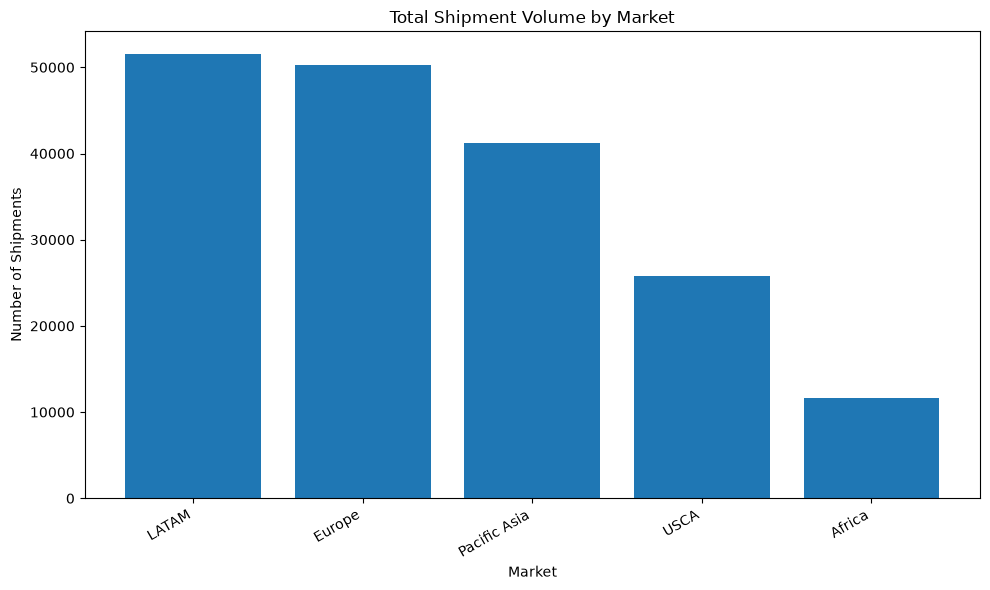

In [19]:
plt.figure(figsize=(10, 6))

plt.bar(
    market_shipment_summary["Market"].astype(str),
    market_shipment_summary["Total_Shipments"]
)

plt.title("Total Shipment Volume by Market")
plt.xlabel("Market")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

## Market Level-Delay Analysis

In [20]:
market_delay_analysis = (
    df_day9
    .groupby("Market", dropna=False)
    .agg(
        Total_Shipments=("Is_Delayed", "size"),
        Total_Delayed_Shipments=("Is_Delayed", "sum"),
        Average_Shipping_Delay_Days=(
            "Shipping_Delay_Days", "mean"
        ),
        Average_Actual_Shipping_Days=(
            "Days for shipping (real)", "mean"
        ),
        Average_Scheduled_Shipping_Days=(
            "Days for shipment (scheduled)", "mean"
        )
    )
    .reset_index()
)

market_delay_analysis["Actual_Delay_Rate_%"] = (
    market_delay_analysis["Total_Delayed_Shipments"]
    / market_delay_analysis["Total_Shipments"]
    * 100
).round(2)

market_delay_analysis[
    [
        "Average_Shipping_Delay_Days",
        "Average_Actual_Shipping_Days",
        "Average_Scheduled_Shipping_Days"
    ]
] = market_delay_analysis[
    [
        "Average_Shipping_Delay_Days",
        "Average_Actual_Shipping_Days",
        "Average_Scheduled_Shipping_Days"
    ]
].round(2)

market_delay_analysis = market_delay_analysis.sort_values(
    "Actual_Delay_Rate_%",
    ascending=False
).reset_index(drop=True)

display(market_delay_analysis)

,Market,Total_Shipments,Total_Delayed_Shipments,Average_Shipping_Delay_Days,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Actual_Delay_Rate_%
0,Europe,50252,28989,0.57,3.49,2.92,57.69
1,Pacific Asia,41260,23649,0.57,3.50,2.93,57.32
2,USCA,25799,14744,0.57,3.48,2.92,57.15
3,LATAM,51594,29420,0.56,3.51,2.95,57.02
4,Africa,11614,6598,0.56,3.51,2.95,56.81


### Visualize Actual Delay Rates by Markets

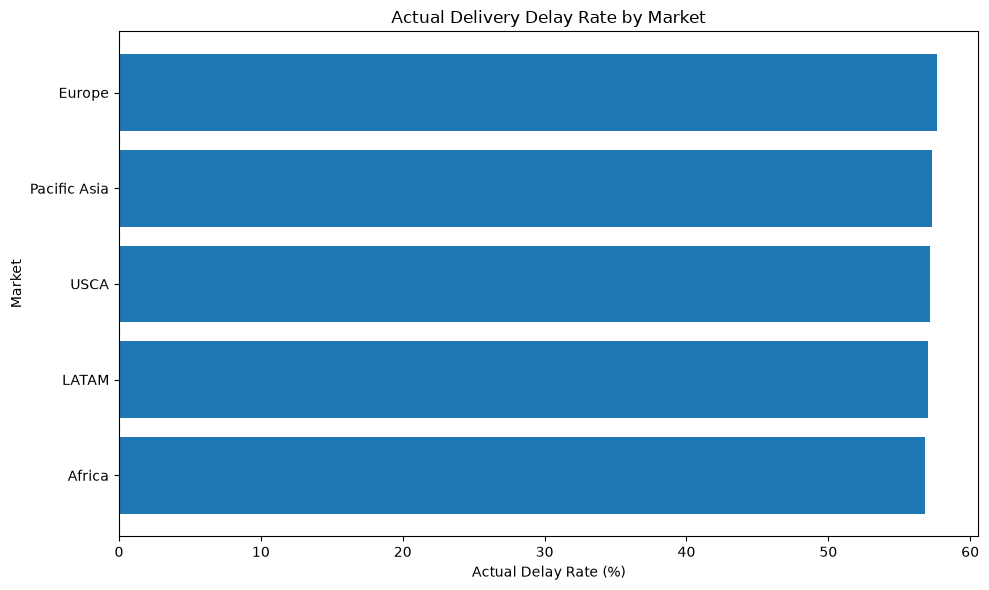

In [21]:
market_delay_plot = market_delay_analysis.sort_values(
    "Actual_Delay_Rate_%",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    market_delay_plot["Market"].astype(str),
    market_delay_plot["Actual_Delay_Rate_%"]
)

plt.title("Actual Delivery Delay Rate by Market")
plt.xlabel("Actual Delay Rate (%)")
plt.ylabel("Market")

plt.tight_layout()
plt.show()

## MArket Delay Severity Analysis

In [22]:
market_delay_severity = pd.crosstab(
    df_day9["Market"],
    df_day9["Delay_Severity"],
    dropna=False
)

display(market_delay_severity)

Delay_Severity,Major Delay,Minor Delay,On Time / Early
Market,,,
Africa,2682,3916,5016
Europe,11867,17122,21263
LATAM,12195,17225,22174
Pacific Asia,9919,13730,17611
USCA,6090,8654,11055


In [23]:
market_delay_severity_pct = (
    pd.crosstab(
        df_day9["Market"],
        df_day9["Delay_Severity"],
        normalize="index",
        dropna=False
    )
    .mul(100)
    .round(2)
)

display(market_delay_severity_pct)

Delay_Severity,Major Delay,Minor Delay,On Time / Early
Market,,,
Africa,23.09,33.72,43.19
Europe,23.61,34.07,42.31
LATAM,23.64,33.39,42.98
Pacific Asia,24.04,33.28,42.68
USCA,23.61,33.54,42.85


## Market Operational & Financial Performance

In [24]:
market_performance = (
    df_day9
    .groupby("Market", dropna=False)
    .agg(
        Total_Shipments=("Market", "size"),
        Total_Sales=("Sales", "sum"),
        Average_Sales_Per_Record=("Sales", "mean"),
        Total_Order_Profit=("Order Profit Per Order", "sum"),
        Average_Order_Profit=(
            "Order Profit Per Order", "mean"
        ),
        Average_Order_Item_Total=("Order Item Total", "mean"),
        Average_Delivery_Efficiency=(
            "Delivery_Efficiency_Ratio", "mean"
        ),
        Actual_Delay_Rate=("Is_Delayed", "mean")
    )
    .reset_index()
)

market_performance["Actual_Delay_Rate_%"] = (
    market_performance["Actual_Delay_Rate"] * 100
).round(2)

market_performance = market_performance.drop(
    columns=["Actual_Delay_Rate"]
)

numeric_columns = market_performance.select_dtypes(
    include="number"
).columns

market_performance[numeric_columns] = (
    market_performance[numeric_columns].round(2)
)

display(market_performance)

,Market,Total_Shipments,Total_Sales,Average_Sales_Per_Record,Total_Order_Profit,Average_Order_Profit,Average_Order_Item_Total,Average_Delivery_Efficiency,Actual_Delay_Rate_%
0,Africa,11614,2294452.88,197.56,252071.18,21.70,177.52,0.91,56.81
1,Europe,50252,10872396.60,216.36,1169442.96,23.27,194.40,0.91,57.69
2,LATAM,51594,10277612.64,199.20,1123321.61,21.77,179.01,0.91,57.02
3,Pacific Asia,41260,8273743.58,200.53,857753.44,20.79,180.18,0.91,57.32
4,USCA,25799,5066528.61,196.38,564313.78,21.87,176.50,0.91,57.15


## Visualize Market Performance

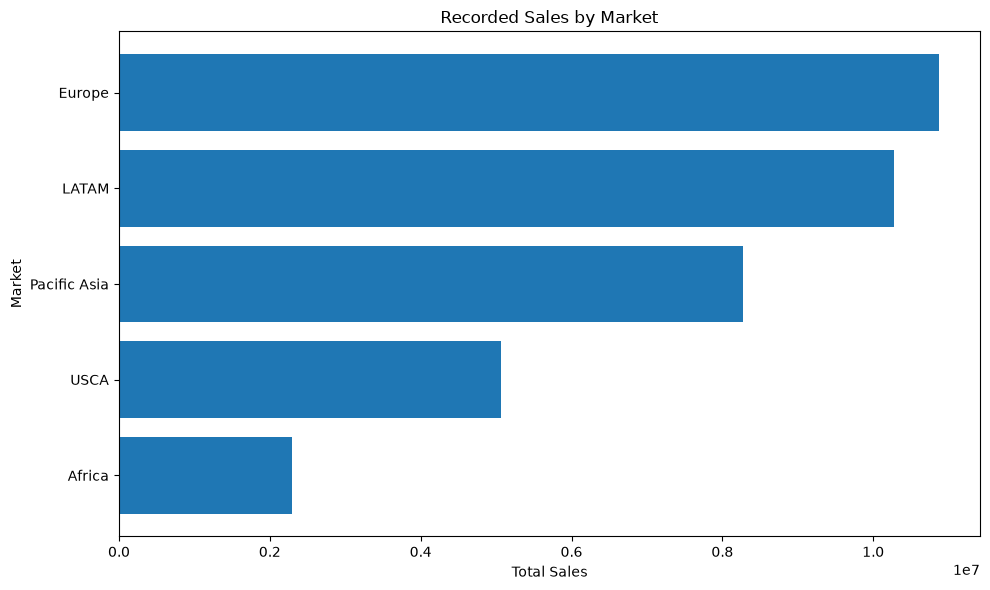

In [25]:
sales_plot = market_performance.sort_values(
    "Total_Sales",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    sales_plot["Market"].astype(str),
    sales_plot["Total_Sales"]
)

plt.title("Recorded Sales by Market")
plt.xlabel("Total Sales")
plt.ylabel("Market")

plt.tight_layout()
plt.show()

## Compare Average Delay Efficiency

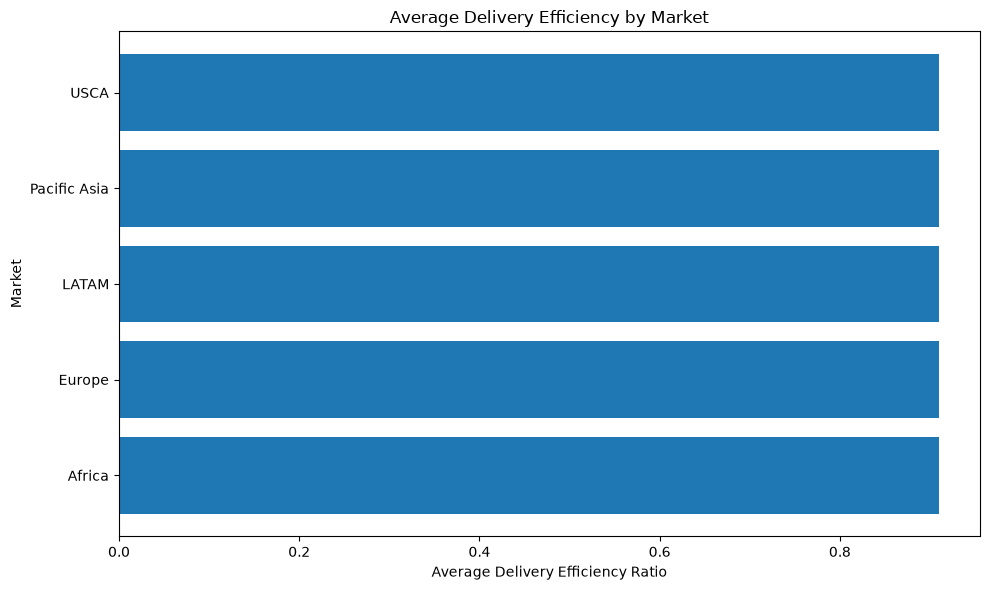

In [26]:
efficiency_plot = market_performance.sort_values(
    "Average_Delivery_Efficiency",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    efficiency_plot["Market"].astype(str),
    efficiency_plot["Average_Delivery_Efficiency"]
)

plt.title("Average Delivery Efficiency by Market")
plt.xlabel("Average Delivery Efficiency Ratio")
plt.ylabel("Market")

plt.tight_layout()
plt.show()

## Day 9 KPI Summary

In [27]:
valid_market_delays = market_delay_analysis.dropna(
    subset=["Market", "Actual_Delay_Rate_%"]
)

if valid_market_delays.empty:
    highest_delay_market = "Unavailable"
    lowest_delay_market = "Unavailable"
else:
    highest_delay_market = (
        valid_market_delays
        .sort_values(
            ["Actual_Delay_Rate_%", "Total_Shipments"],
            ascending=[False, False]
        )
        .iloc[0]["Market"]
    )

    lowest_delay_market = (
        valid_market_delays
        .sort_values(
            ["Actual_Delay_Rate_%", "Total_Shipments"],
            ascending=[True, False]
        )
        .iloc[0]["Market"]
    )

market_shipment_ranking = (
    market_shipment_summary
    .dropna(subset=["Market"])
    .sort_values(
        ["Total_Shipments", "Market"],
        ascending=[False, True]
    )
)

highest_volume_market = (
    market_shipment_ranking.iloc[0]["Market"]
    if not market_shipment_ranking.empty
    else "Unavailable"
)

lowest_volume_market = (
    market_shipment_ranking.iloc[-1]["Market"]
    if not market_shipment_ranking.empty
    else "Unavailable"
)

day9_kpis = pd.DataFrame({
    "Metric": [
        "Total Shipment Records",
        "Unique Markets",
        "Missing Market Records",
        "Overall Actual Delay Rate (%)",
        "Total Delayed Shipments",
        "Highest Delay Rate Market",
        "Lowest Delay Rate Market",
        "Highest Volume Market",
        "Lowest Volume Market"
    ],

    "Value": [
        len(df_day9),
        df_day9["Market"].nunique(dropna=True),
        df_day9["Market"].isna().sum(),
        round(df_day9["Is_Delayed"].mean() * 100, 2),
        int(df_day9["Is_Delayed"].sum()),
        highest_delay_market,
        lowest_delay_market,
        highest_volume_market,
        lowest_volume_market
    ]
})

display(day9_kpis)

,Metric,Value
0,Total Shipment Records,180519
1,Unique Markets,5
2,Missing Market Records,0
3,Overall Actual Delay Rate (%),57.28
4,Total Delayed Shipments,103400
5,Highest Delay Rate Market,Europe
6,Lowest Delay Rate Market,Africa
7,Highest Volume Market,LATAM
8,Lowest Volume Market,Africa


## Validate Day 9 Result

### Validate the number of market categories

In [29]:
print("Unique markets:", df_day9["Market"].nunique(dropna=True))

print(
    "Market shipment summary total:",
    market_shipment_summary["Total_Shipments"].sum()
)

print("Dataset rows:", len(df_day9))

Unique markets: 5
Market shipment summary total: 180519
Dataset rows: 180519


### Validate actual delay values

In [30]:
print("Unique Is_Delayed values:")
print(sorted(df_day9["Is_Delayed"].dropna().unique()))

print("Missing Is_Delayed values:",
      df_day9["Is_Delayed"].isna().sum())

print("Invalid Is_Delayed values:",
      (~df_day9["Is_Delayed"].isin([0, 1])).sum())

Unique Is_Delayed values:
[np.int64(0), np.int64(1)]
Missing Is_Delayed values: 0
Invalid Is_Delayed values: 0


### Validate the dely-rate bounds 

In [31]:
delay_rate_valid = (
    market_delay_analysis["Actual_Delay_Rate_%"]
    .dropna()
    .between(0, 100)
    .all()
)

print("All market delay rates between 0 and 100%:",
      delay_rate_valid)

All market delay rates between 0 and 100%: True


### Validate market shipment totals

In [32]:
market_totals_valid = (
    market_shipment_summary["Total_Shipments"].sum()
    == len(df_day9)
)

print("Market shipment totals reconcile:",
      market_totals_valid)

Market shipment totals reconcile: True


### Validate market categories

In [33]:
expected_markets = {
    "Africa",
    "Europe",
    "LATAM",
    "Pacific Asia",
    "USCA"
}

observed_markets = set(
    df_day9["Market"].dropna().unique()
)

print("Expected markets:", sorted(expected_markets))
print("Observed markets:", sorted(observed_markets))

print(
    "Expected markets present:",
    expected_markets.issubset(observed_markets)
)

print(
    "Unexpected market categories:",
    sorted(observed_markets - expected_markets)
)

Expected markets: ['Africa', 'Europe', 'LATAM', 'Pacific Asia', 'USCA']
Observed markets: ['Africa', 'Europe', 'LATAM', 'Pacific Asia', 'USCA']
Expected markets present: True
Unexpected market categories: []


## Saving Day 9 Outputs

In [34]:
day9_output_dir = Path("../data/analysis_data/")

if not day9_output_dir.exists():
    raise FileNotFoundError(
        f"Output directory does not exist: {day9_output_dir}"
    )

day9_outputs = {
    "APL_Day9_Market_Shipment_Summary.csv":
        market_shipment_summary,

    "APL_Day9_Market_Delay_Analysis.csv":
        market_delay_analysis,

    "APL_Day9_Market_Delay_Severity.csv":
        market_delay_severity_pct.reset_index(),

    "APL_Day9_Market_Performance.csv":
        market_performance,

    "APL_Day9_KPIs.csv":
        day9_kpis
}

### Create the validation dataframe

In [35]:
day9_validation = pd.DataFrame({
    "Validation_Check": [
        "Expected columns available",
        "Market shipment totals reconcile",
        "Delay rate bounds valid",
        "All expected markets present",
        "No duplicate source rows"
    ],

    "Result": [
        len(missing_columns) == 0,
        market_totals_valid,
        delay_rate_valid,
        expected_markets.issubset(observed_markets),
        df_day9.duplicated().sum() == 0
    ]
})

day9_outputs["APL_Day9_Validation.csv"] = day9_validation

display(day9_validation)

,Validation_Check,Result
0,Expected columns available,True
1,Market shipment totals reconcile,True
2,Delay rate bounds valid,True
3,All expected markets present,True
4,No duplicate source rows,True


In [36]:
for filename, output_df in day9_outputs.items():

    output_path = day9_output_dir / filename

    output_df.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    print("Saved:", output_path)

Saved: ..\data\analysis_data\APL_Day9_Market_Shipment_Summary.csv
Saved: ..\data\analysis_data\APL_Day9_Market_Delay_Analysis.csv
Saved: ..\data\analysis_data\APL_Day9_Market_Delay_Severity.csv
Saved: ..\data\analysis_data\APL_Day9_Market_Performance.csv
Saved: ..\data\analysis_data\APL_Day9_KPIs.csv
Saved: ..\data\analysis_data\APL_Day9_Validation.csv
